<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS09/datasetPBL/Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif, SequentialFeatureSelector
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load dan gabungkan dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))
df = df.dropna(subset=['text', 'rating_review']).copy()

# 2. Ekstraksi fitur numerik & fitur statistik teks ulasan
df['panjang_teks'] = df['text'].astype(str).apply(len)
df['jumlah_kata'] = df['text'].astype(str).apply(lambda x: len(x.split()))
df['jumlah_tanda_seru'] = df['text'].astype(str).apply(lambda x: x.count('!'))
df['jumlah_huruf_kapital'] = df['text'].astype(str).apply(lambda x: sum(1 for c in x if c.isupper()))

fitur_kandidat = [
    'rating_cafe',
    'review_count',
    'latitude',
    'longitude',
    'panjang_teks',
    'jumlah_kata',
    'jumlah_tanda_seru',
    'jumlah_huruf_kapital'
]

# Target biner: 'Positif' (rating_review >= 4) vs 'Negatif' (rating_review < 4)
X = df[fitur_kandidat].fillna(0)
y = np.where(df['rating_review'] >= 4, 'Positif', 'Negatif')

print("Shape Fitur X:", X.shape)
print("Distribusi Kelas Target:\n", pd.Series(y).value_counts())

Shape Fitur X: (2230, 8)
Distribusi Kelas Target:
 Positif    1986
Negatif     244
Name: count, dtype: int64


In [2]:
# Split data 70% training, 30% testing secara stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Standardisasi fitur (wajib untuk kNN berbasis jarak Euclidean)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model kNN baseline (k = 5)
knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_scaled, y_train)
y_pred_base = knn_base.predict(X_test_scaled)

print("=== SOAL 1: HASIL BASELINE kNN (SEMUA 8 FITUR, k=5) ===")
print(f"Akurasi Testing : {accuracy_score(y_test, y_pred_base):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_base))
print("\nClassification Report:\n", classification_report(y_test, y_pred_base))

=== SOAL 1: HASIL BASELINE kNN (SEMUA 8 FITUR, k=5) ===
Akurasi Testing : 0.8834

Confusion Matrix:
 [[ 11  62]
 [ 16 580]]

Classification Report:
               precision    recall  f1-score   support

     Negatif       0.41      0.15      0.22        73
     Positif       0.90      0.97      0.94       596

    accuracy                           0.88       669
   macro avg       0.66      0.56      0.58       669
weighted avg       0.85      0.88      0.86       669



=== PERINGKAT SKOR TIAP FITUR (ANOVA F-TEST) ===
               Fitur  ANOVA_F_Score      P_Value
         jumlah_kata      38.488935 7.040702e-10
         rating_cafe      38.116697 8.481443e-10
        panjang_teks      33.158175 1.021461e-08
        review_count      11.021307 9.214952e-04
   jumlah_tanda_seru       1.873161 1.713107e-01
            latitude       1.715220 1.905025e-01
           longitude       1.487957 2.227182e-01
jumlah_huruf_kapital       0.242616 6.223925e-01

=== PERBANDINGAN AKURASI BERDASARKAN SUBSET FITUR ===
 Jumlah_Fitur  CV_Accuracy  Test_Accuracy                                                                                                       Daftar_Fitur
            1       0.8847         0.8774                                                                                                        jumlah_kata
            2       0.8808         0.8879                                                                                           jumlah_ka

/tmp/ipykernel_378/1254910554.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_skor_fitur, x='ANOVA_F_Score', y='Fitur', palette='viridis')


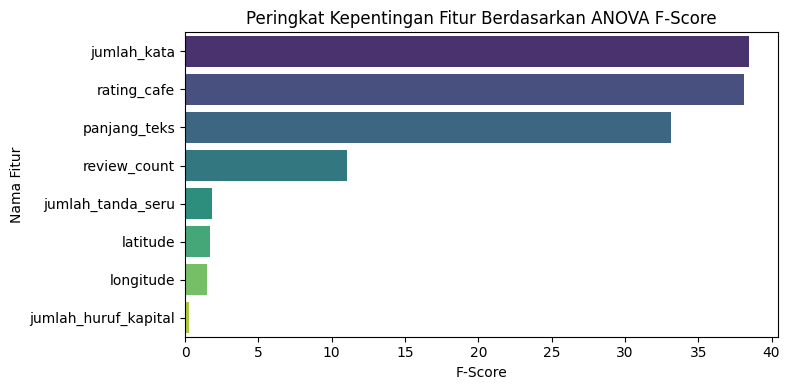

In [3]:
# 1. Hitung skor korelasi ANOVA F-value tiap fitur terhadap target
selector_anova = SelectKBest(score_func=f_classif, k='all')
selector_anova.fit(X_train_scaled, y_train)

df_skor_fitur = pd.DataFrame({
    'Fitur': fitur_kandidat,
    'ANOVA_F_Score': selector_anova.scores_,
    'P_Value': selector_anova.pvalues_
}).sort_values(by='ANOVA_F_Score', ascending=False)

print("=== PERINGKAT SKOR TIAP FITUR (ANOVA F-TEST) ===")
print(df_skor_fitur.to_string(index=False))

# 2. Uji akurasi cross-validation untuk setiap jumlah subset fitur terbaik (1 sampai 8 fitur)
hasil_subset = []
for n_feat in range(1, len(fitur_kandidat) + 1):
    top_feats = df_skor_fitur['Fitur'].iloc[:n_feat].tolist()
    X_sub_tr = scaler.fit_transform(X_train[top_feats])
    X_sub_te = scaler.transform(X_test[top_feats])

    model = KNeighborsClassifier(n_neighbors=5)
    cv_acc = cross_val_score(model, X_sub_tr, y_train, cv=5, scoring='accuracy').mean()
    model.fit(X_sub_tr, y_train)
    test_acc = model.score(X_sub_te, y_test)

    hasil_subset.append({
        'Jumlah_Fitur': n_feat,
        'Daftar_Fitur': ", ".join(top_feats),
        'CV_Accuracy': round(cv_acc, 4),
        'Test_Accuracy': round(test_acc, 4)
    })

df_subset = pd.DataFrame(hasil_subset)
print("\n=== PERBANDINGAN AKURASI BERDASARKAN SUBSET FITUR ===")
print(df_subset[['Jumlah_Fitur', 'CV_Accuracy', 'Test_Accuracy', 'Daftar_Fitur']].to_string(index=False))

# Ambil subset fitur dengan Test_Accuracy tertinggi
best_row = df_subset.loc[df_subset['Test_Accuracy'].idxmax()]
fitur_optimal = best_row['Daftar_Fitur'].split(', ')
print(f"\n-> Fitur Paling Optimal ({best_row['Jumlah_Fitur']} fitur): {fitur_optimal}")
print(f"-> Akurasi Testing Optimal: {best_row['Test_Accuracy']:.4f}")

# Visualisasi bar chart F-Score fitur
plt.figure(figsize=(8, 4))
sns.barplot(data=df_skor_fitur, x='ANOVA_F_Score', y='Fitur', palette='viridis')
plt.title('Peringkat Kepentingan Fitur Berdasarkan ANOVA F-Score')
plt.xlabel('F-Score')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

=== SOAL 3: NILAI K TERBAIK ===
Nilai K terbaik          : k = 22
Akurasi Testing Terbaik  : 0.8924
Akurasi Training (k=22)  : 0.8911


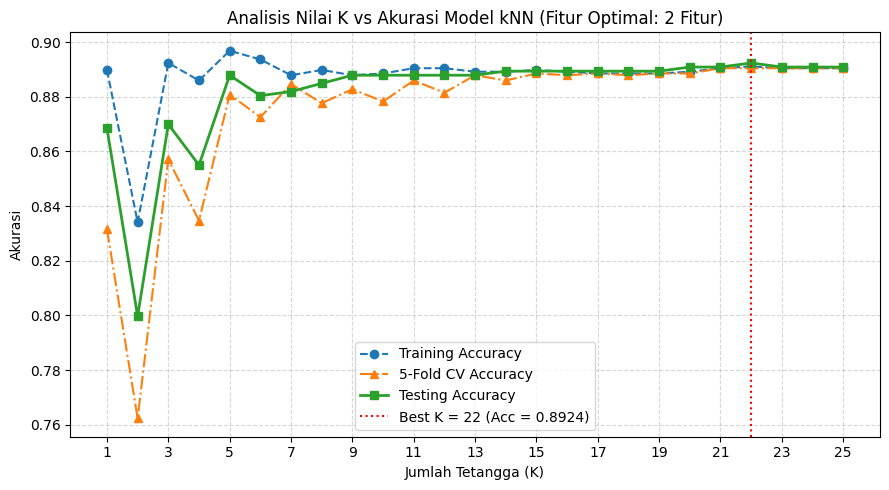

In [4]:
# Gunakan hanya fitur optimal dari Soal 2
scaler_opt = StandardScaler()
X_train_opt = scaler_opt.fit_transform(X_train[fitur_optimal])
X_test_opt = scaler_opt.transform(X_test[fitur_optimal])

k_values = range(1, 26)
train_scores = []
test_scores = []
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_scores.append(cross_val_score(knn, X_train_opt, y_train, cv=5, scoring='accuracy').mean())
    knn.fit(X_train_opt, y_train)
    train_scores.append(knn.score(X_train_opt, y_train))
    test_scores.append(knn.score(X_test_opt, y_test))

best_k_idx = int(np.argmax(test_scores))
best_k = list(k_values)[best_k_idx]
best_acc = test_scores[best_k_idx]

print(f"=== SOAL 3: NILAI K TERBAIK ===")
print(f"Nilai K terbaik          : k = {best_k}")
print(f"Akurasi Testing Terbaik  : {best_acc:.4f}")
print(f"Akurasi Training (k={best_k})  : {train_scores[best_k_idx]:.4f}")

# Grafik Analisis Nilai K vs Akurasi (Training, Cross-Validation, dan Testing)
plt.figure(figsize=(9, 5))
plt.plot(k_values, train_scores, marker='o', linestyle='--', label='Training Accuracy')
plt.plot(k_values, cv_scores, marker='^', linestyle='-.', label='5-Fold CV Accuracy')
plt.plot(k_values, test_scores, marker='s', linewidth=2, label='Testing Accuracy')
plt.axvline(x=best_k, color='red', linestyle=':', label=f'Best K = {best_k} (Acc = {best_acc:.4f})')

plt.title(f'Analisis Nilai K vs Akurasi Model kNN (Fitur Optimal: {len(fitur_optimal)} Fitur)')
plt.xlabel('Jumlah Tetangga (K)')
plt.ylabel('Akurasi')
plt.xticks(range(1, 26, 2))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()